In [1]:
import sys
import deepimpact.solver as s
import numpy as np

In [2]:
import sys

import deepimpact.solver as s
print(s.__file__)

/home/fc426/ACSE/ACDS/acds-deep-impact-gaspra/deepimpact/solver.py


In [3]:
%reload_ext autoreload
%autoreload 2

planet = s.Planet()
result = planet.solve_atmospheric_entry(
    radius=10, velocity=19.2e3, density=3300,
    strength=1e6, angle=18.3)
result

stop: z=-0.6 v=52.12 m=2.17e+06 theta=1.5698 steps=10298
ground


,velocity,mass,angle,altitude,distance,radius,spreading_rate,time
0,19200.000000,1.382301e+07,18.300000,100000.000000,0.000000,10.0,0.0,0.000000
1,19200.153032,1.382301e+07,18.293319,99698.619180,897.405109,10.0,0.0,0.050000
2,19200.305972,1.382300e+07,18.286638,99397.342246,1794.893758,10.0,0.0,0.100000
3,19200.458820,1.382300e+07,18.279955,99096.169218,2692.465928,10.0,0.0,0.150000
4,19200.611575,1.382300e+07,18.273272,98795.100114,3590.121599,10.0,0.0,0.200000
...,...,...,...,...,...,...,...,...
5144,52.151305,2.166990e+06,89.941651,9.812029,250251.554577,65.0,0.0,257.200000
5145,52.142647,2.166989e+06,89.941651,7.204681,250251.557232,65.0,0.0,257.250000
5146,52.133993,2.166989e+06,89.941652,4.597767,250251.559887,65.0,0.0,257.300000
5147,52.125341,2.166988e+06,89.941652,1.991285,250251.562541,65.0,0.0,257.350000


In [4]:
import numpy as np

ref = np.load("tests/scenario.npz")
rho = 1.2 * np.exp(-ref["altitude"] / 8000)
ram = rho * ref["velocity"]**2

i = np.argmax(ref["radius"] > 35)      # first row where it spreads
print(i, ram[i-1], ram[i])             # strength lies between these (roughly)

21 6963357.258678906 10553940.5748966


In [5]:
planet = s.Planet()
res = planet.solve_atmospheric_entry(radius=35, velocity=19000, density=3000,
                                     strength=10000000, angle=45, dt=0.25)

n = len(ref["altitude"])
for name in ['velocity', 'altitude', 'mass', 'radius', 'angle', 'distance']:
    mine = res[name].values[:n]
    r = ref[name]
    mask = r != 0
    err = np.abs(mine[mask] - r[mask]) / np.abs(r[mask])
    print(name, err.max())

stop: z=-1.9 v=96.68 m=8.78e+07 theta=1.4999 steps=839
ground
velocity 1.5011815765078776e-05
altitude 1.2474880178963313e-05
mass 4.635599066361438e-06
radius 1.1521568277075889e-05
angle 2.4717095383776384e-07
distance 5.614795903000657e-07


In [6]:
for name in ['velocity', 'mass', 'radius', 'altitude']:
    mine = res[name].values[:n]
    err = np.abs(mine - ref[name]) / np.abs(ref[name])
    print(name, np.nonzero(err > 1e-4)[0][:3], err.max())

velocity [] 1.5011815765078776e-05
mass [] 4.635599066361438e-06
radius [] 1.1521568277075889e-05
altitude [] 1.2474880178963313e-05


Text(0, 0.5, 'velocity (m/s)')

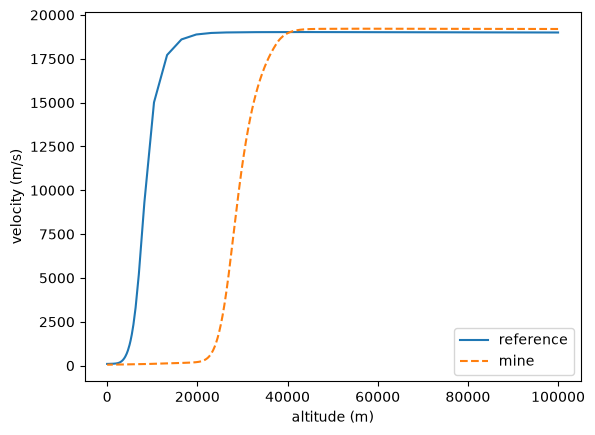

In [7]:
import matplotlib.pyplot as plt
plt.plot(res['altitude'], res['velocity'], label="reference")
plt.plot(result.altitude, result.velocity, "--", label="mine")
plt.legend(); plt.xlabel("altitude (m)"); plt.ylabel("velocity (m/s)")

In [8]:
for Y in [7e6, 8e6, 9e6, 1e7, 1.1e7]:
    res = planet.solve_atmospheric_entry(radius=35, velocity=19000, density=3000,
                                         strength=Y, angle=45, dt=0.25)

    if Y == 7e6:
        display(res)
    k = min(len(res), n)
    for name in ['velocity', 'mass', 'radius']:
        err = np.abs(res[name].values[:k] - ref[name][:k]) / ref[name][:k]
        print(f"{Y:.0e}", name, err.max())

stop: z=-4.8 v=96.68 m=8.78e+07 theta=1.5084 steps=872
ground


,velocity,mass,angle,altitude,distance,radius,spreading_rate,time
0,19000.000000,5.387831e+08,45.000000,100000.000000,0.000000,35.0,0.0,0.000000
1,19001.732017,5.387830e+08,44.975476,96641.808504,3308.569415,35.0,0.0,0.250000
2,19003.462356,5.387827e+08,44.950922,93284.750349,6620.575462,35.0,0.0,0.500000
3,19005.190529,5.387823e+08,44.926340,89928.828462,9936.022131,35.0,0.0,0.750000
4,19006.915795,5.387816e+08,44.901728,86574.045879,13254.913311,35.0,0.0,1.000000
...,...,...,...,...,...,...,...,...
170,97.289231,8.775573e+07,86.052009,92.012922,98235.604224,227.5,0.0,42.500000
171,97.135681,8.775551e+07,86.148761,67.766086,98237.256948,227.5,0.0,42.750000
172,96.982729,8.775529e+07,86.243255,43.554754,98238.866669,227.5,0.0,43.000000
173,96.830355,8.775507e+07,86.335541,19.378916,98240.434463,227.5,0.0,43.250000


7e+06 velocity 0.04279417994060431
7e+06 mass 0.07587112832033478
7e+06 radius 0.17043822584239304
stop: z=-0.2 v=96.70 m=8.78e+07 theta=1.5054 steps=860
ground
8e+06 velocity 0.02882348801164743
8e+06 mass 0.050555812884960256
8e+06 radius 0.10878809357910682
stop: z=-4.0 v=96.67 m=8.78e+07 theta=1.5029 steps=850
ground
9e+06 velocity 0.014554397028881201
9e+06 mass 0.025246920428216673
9e+06 radius 0.052072412313743766
stop: z=-1.9 v=96.68 m=8.78e+07 theta=1.4999 steps=839
ground
1e+07 velocity 1.5011815765078776e-05
1e+07 mass 4.635599066361438e-06
1e+07 radius 1.1521568277075889e-05
stop: z=-3.7 v=96.66 m=8.78e+07 theta=1.4971 steps=829
ground
1e+07 velocity 0.014843251796147488
1e+07 mass 0.02513057739235506
1e+07 radius 0.04766076614605004


19000.0


Text(0, 0.5, 'velocity (m/s)')

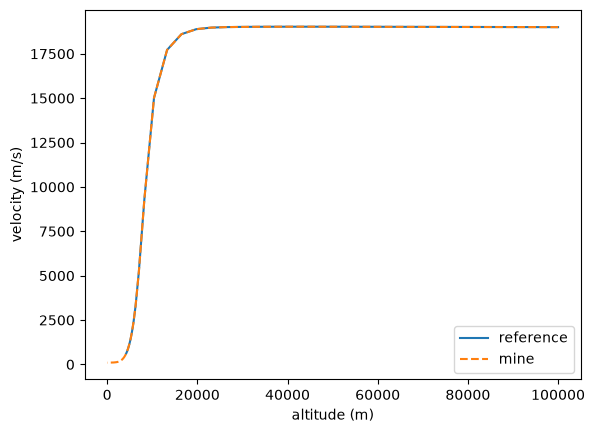

In [22]:
res = planet.solve_atmospheric_entry(radius=35, velocity=19000, density=3000,
                                     strength=1e7, angle=45, dt=0.25)
print(res.velocity.iloc[0])    # must print 19000.0

plt.plot(ref["altitude"], ref["velocity"], label="reference")
plt.plot(res.altitude, res.velocity, "--", label="mine")
plt.legend(); plt.xlabel("altitude (m)"); plt.ylabel("velocity (m/s)")

[    0.  2000.  4000.  6000.  8000. 10000. 12000. 14000. 16000. 18000.
 20000. 22000. 24000. 26000. 28000. 30000. 32000. 34000. 36000. 38000.
 40000. 42000. 44000. 46000. 48000. 50000. 52000. 54000. 56000. 58000.
 60000. 62000. 64000. 66000. 68000. 70000. 72000. 74000. 76000. 78000.
 80000. 82000. 84000. 86000.]
[1.22500e+00 1.00649e+00 8.19129e-01 6.59697e-01 5.25168e-01 4.12707e-01
 3.10828e-01 2.26753e-01 1.65420e-01 1.20676e-01 8.80349e-02 6.37273e-02
 4.62674e-02 3.36882e-02 2.45988e-02 1.80119e-02 1.32250e-02 9.60889e-03
 7.03441e-03 5.18691e-03 3.85101e-03 2.87802e-03 2.16443e-03 1.63760e-03
 1.25825e-03 9.77525e-04 7.66867e-04 6.05252e-04 4.75263e-04 3.71207e-04
 2.88321e-04 2.22640e-04 1.70875e-04 1.30308e-04 9.87069e-05 7.42430e-05
 5.52370e-05 4.07010e-05 2.98135e-05 2.17046e-05 1.57005e-05 1.12820e-05
 8.05100e-06 5.64114e-06]
0.9596497500000001


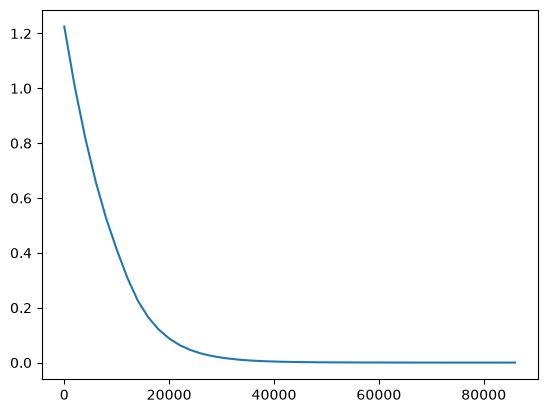

In [10]:
densities = np.genfromtxt('resources/AltitudeDensityTable.csv', delimiter='   ')
data = np.loadtxt("resources/AltitudeDensityTable.csv")   # '#' header lines are ignored by default
altitude = data[:, 0]
density = data[:, 1]
rhoa = lambda z: np.interp(z, altitude, density)

print(altitude)
print(density)

import matplotlib.pyplot as plt

plt.plot(altitude, density)

print(rhoa(2500))

In [11]:
p = s.Planet(atmos_func='tabular')
print(p.rhoa(0), p.rhoa(20e3), p.rhoa(100e3))   # 1.225, 0.088, and no nan

for dt in [0.25, 0.05, 0.03, 0.055]:
    df = s.Planet().solve_atmospheric_entry(35, 19000, 3000, 1e7, 45, dt=dt)
    print(dt, len(df), np.allclose(np.diff(df.time)[:-1], dt), df.altitude.iloc[-1])

1.225 0.08803489999999999 0.0


0.25 169 True 0.0
0.05 838 True 0.0
0.03 1396 True 0.0
0.055 762 True 0.0


In [12]:
import timeit
import deepimpact

p = deepimpact.Planet()
args = dict(radius=35, velocity=19000, density=3000, strength=1e7, angle=45, dt=0.05)

t = timeit.repeat(lambda: p.solve_atmospheric_entry(**args), number=5, repeat=5)
print(f"best per call: {min(t) / 5 * 1000:.1f} ms")

best per call: 36.2 ms


In [13]:
import inspect
print("NotImplementedError" in inspect.getsource(s.Planet.__init__))

False


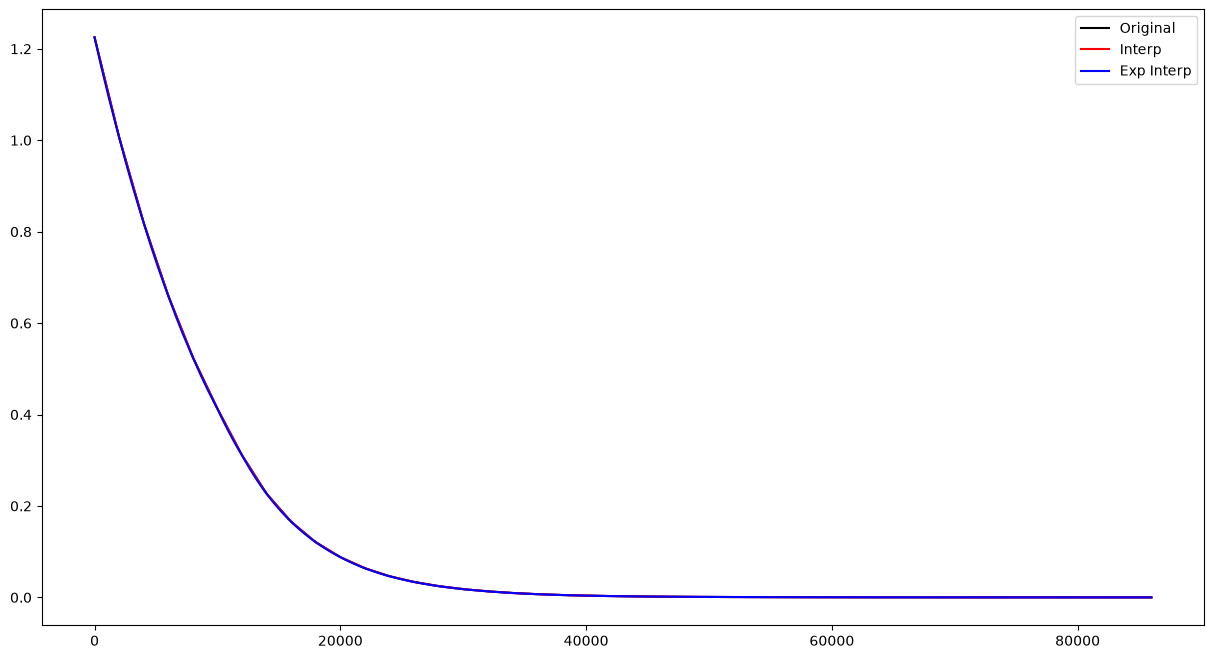

In [14]:
import matplotlib.pyplot as plt

alt_rho_data = np.loadtxt("resources/AltitudeDensityTable.csv")
altitude = alt_rho_data[:, 0]
rho = alt_rho_data[:, 1]

rhoa_1 = lambda z: np.interp(z, altitude, rho, right=0.0)
rhoa_2 = lambda z: np.exp(np.interp(z, altitude, np.log(rho), right=-np.inf))

z_min = min(altitude)
z_max = max(altitude)
zz = np.linspace(z_min, z_max, 300)
density_1 = rhoa_1(zz)
density_2 = rhoa_2(zz)

plt.figure(figsize=(15,8))
plt.plot(altitude, rho, 'black', label='Original')
plt.plot(zz, density_1, 'r', label='Interp')
plt.plot(zz, density_2, 'blue', label='Exp Interp')
plt.legend()
plt.show()

In [15]:
import numpy as np
import pandas as pd
import deepimpact

planet = deepimpact.Planet()

scenario = dict(
    radius=35.0,
    velocity=19e3,
    density=3000.0,
    strength=1e7,
    angle=45.0,
)

# Treat this fine run as an approximate reference.
reference_dt = 0.00625
reference = planet.solve_atmospheric_entry(**scenario, dt=reference_dt)

# Compare reconstructions from progressively finer output runs.
test_dts = [0.2, 0.1, 0.05, 0.025]
coarse_runs = {
    dt: planet.solve_atmospheric_entry(**scenario, dt=dt)
    for dt in test_dts
}

In [16]:
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d

data = np.loadtxt(
    "resources/AltitudeDensityTable.csv",
    comments="#",
)
altitude, rho = data[:, 0], data[:, 1]

stride = 5  # Table spacing is 2 km, so anchors are about 10 km apart
all_indices = np.arange(len(altitude))
predictions = {"linear": [], "exponential": [], "quadratic": []}
truths = []

# Try each possible starting offset to reduce dependence on which rows
# happen to be selected as anchors.
for offset in range(stride):
    train_idx = np.unique(np.r_[
        np.arange(offset, len(altitude), stride),
        0,
        len(altitude) - 1,
    ])
    test_idx = np.setdiff1d(all_indices, train_idx)

    z_train, rho_train = altitude[train_idx], rho[train_idx]
    z_test, rho_test = altitude[test_idx], rho[test_idx]

    linear = np.interp(z_test, z_train, rho_train)

    # Log-linear interpolation: interpolate log(density), then exponentiate.
    exponential = np.exp(
        np.interp(z_test, z_train, np.log(rho_train))
    )

    quadratic_fn = interp1d(
        z_train, rho_train, kind="quadratic", bounds_error=True
    )
    quadratic = quadratic_fn(z_test)

    truths.append(rho_test)
    predictions["linear"].append(linear)
    predictions["exponential"].append(exponential)
    predictions["quadratic"].append(quadratic)

truth = np.concatenate(truths)

scores = []
for method, parts in predictions.items():
    estimate = np.concatenate(parts)
    relative_error = (estimate - truth) / truth

    scores.append({
        "method": method,
        "relative RMSE (%)": 100 * np.sqrt(np.mean(relative_error**2)),
        "maximum absolute relative error (%)":
            100 * np.max(np.abs(relative_error)),
        "nonpositive predictions": int(np.count_nonzero(estimate <= 0)),
    })

pd.DataFrame(scores).sort_values("relative RMSE (%)").round(3)

,method,relative RMSE (%),maximum absolute relative error (%),nonpositive predictions
1,exponential,2.304,8.160,0
2,quadratic,4.585,24.600,0
0,linear,22.196,36.609,0


In [17]:
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d, PchipInterpolator
import deepimpact

# Load the tabulated atmosphere.
data = np.loadtxt("resources/AltitudeDensityTable.csv", comments="#")
altitude, rho = data[:, 0], data[:, 1]
log_rho = np.log(rho)

# Candidate interpolation functions.
quadratic_log = interp1d(altitude, log_rho, kind="quadratic")
pchip_log = PchipInterpolator(altitude, log_rho)

def bounded_rhoa(interpolator, log_space=False):
    """Apply the same out-of-table behavior to every candidate."""
    def rhoa(z):
        if z < altitude[0]:
            return float(rho[0])
        if z > altitude[-1]:
            return 0.0  # Matches the current right=0.0 behavior.
        value = float(interpolator(z))
        return float(np.exp(value)) if log_space else value
    return rhoa

atmospheres = {
    "linear density": bounded_rhoa(
        lambda z: np.interp(z, altitude, rho)
    ),
    "linear log-density": bounded_rhoa(
        lambda z: np.interp(z, altitude, log_rho), log_space=True
    ),
    "quadratic log-density": bounded_rhoa(
        quadratic_log, log_space=True
    ),
    "PCHIP log-density (baseline)": bounded_rhoa(
        pchip_log, log_space=True
    ),
}

# Replace these with the exact inputs for your scenario one.
scenario_one = {
    "radius": 35.0,
    "velocity": 19e3,
    "density": 3000.0,
    "strength": 1e7,
    "angle": 45.0,
    "init_altitude": 100e3,
}
dt = 0.05

scenario_one = {
    "radius": 10.0,          # m
    "velocity": 19.2e3,      # m/s
    "density": 3300.0,       # kg/m^3
    "strength": 1.0e6,       # Pa
    "angle": 18.3,           # degrees
    "init_altitude": 100e3,  # m
}
dt = 0.05

# Run each atmosphere with the same solver settings.
runs = {}
for name, rhoa in atmospheres.items():
    planet = deepimpact.Planet(atmos_func="constant")
    planet.rhoa = rhoa
    runs[name] = planet.solve_atmospheric_entry(**scenario_one, dt=dt)

# One row per run, with endpoint differences from the PCHIP baseline.
reference_name = "PCHIP log-density (baseline)"
reference_end = runs[reference_name].iloc[-1]

rows = []
for name, result in runs.items():
    end = result.iloc[-1]
    row = {
        "method": name,
        "rows": len(result),
        "final_altitude_m": end["altitude"],
        "final_time_s": end["time"],
        "final_distance_m": end["distance"],
        "final_velocity_m_s": end["velocity"],
        "final_mass_kg": end["mass"],
    }
    for column in ["distance", "velocity", "mass"]:
        row[f"{column}_delta_from_baseline"] = (
            end[column] - reference_end[column]
        )
    rows.append(row)

summary = pd.DataFrame(rows).set_index("method")
summary

,rows,final_altitude_m,final_time_s,final_distance_m,final_velocity_m_s,final_mass_kg,distance_delta_from_baseline,velocity_delta_from_baseline,mass_delta_from_baseline
method,,,,,,,,,
linear density,5095,0.0,254.675554,258472.704092,51.450180,2.166987e+06,-177.474014,-0.020947,-0.023517
linear log-density,5078,0.0,253.807922,258648.845215,51.478419,2.166987e+06,-1.332892,0.007292,0.008129
quadratic log-density,5080,0.0,253.933993,258650.071124,51.471192,2.166987e+06,-0.106983,0.000065,0.000071
PCHIP log-density (baseline),5080,0.0,253.933613,258650.178106,51.471127,2.166987e+06,0.000000,0.000000,0.000000


In [18]:
reference = np.load("tests/scenario.npz")
columns = ["velocity", "mass", "radius"]

for dt in [0.05, 0.04, 0.03, 0.025, 0.0125, 0.01]:
    planet = deepimpact.Planet()
    result = planet.solve_atmospheric_entry(
        radius=35.0, velocity=19000.0, density=3000.0,
        strength=1e7, angle=45.0, init_altitude=100000.0, dt=dt,
    )

    print(f"\ndt={dt}")
    for column in columns:
        actual = np.interp(
            reference["altitude"],
            result["altitude"].to_numpy()[::-1],
            result[column].to_numpy()[::-1],
        )
        scale = np.maximum(np.abs(reference[column]), 1.0)
        max_rel_error = np.max(np.abs(actual - reference[column]) / scale)
        print(f"{column}: max relative error = {max_rel_error:.3%}")


dt=0.05
velocity: max relative error = 0.008%
mass: max relative error = 0.001%
radius: max relative error = 0.001%

dt=0.04
velocity: max relative error = 0.085%
mass: max relative error = 0.072%
radius: max relative error = 0.069%

dt=0.03
velocity: max relative error = 0.025%
mass: max relative error = 0.081%
radius: max relative error = 0.034%

dt=0.025
velocity: max relative error = 0.008%
mass: max relative error = 0.001%
radius: max relative error = 0.001%

dt=0.0125
velocity: max relative error = 0.008%
mass: max relative error = 0.001%
radius: max relative error = 0.001%

dt=0.01
velocity: max relative error = 0.008%
mass: max relative error = 0.001%
radius: max relative error = 0.001%


In [19]:
res = planet.solve_atmospheric_entry(35, 19000, 3000, 1e7, 45, dt=0.25)
print(res[res.radius > 0.999 * 6.5 * 35].spreading_rate.abs().max())   # must be 0.0

0.0
